In [1]:
## Librerías del cuaderno de priorización
import os, json, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import joblib



pd.set_option('display.max_columns', 80)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
## Carga de los datos y del modelo guardado por el cuaderno 1; se reconstruyen aj, D y tab con la interfaz que usa la sección 12
CARPETA_MODELO = 'Data/processed/modelo_fds'
with open(f'{CARPETA_MODELO}/config.json', encoding='utf-8') as f:
    cfg = json.load(f)

SEMILLA, K_PLIEGUES = cfg['SEMILLA'], cfg['K_PLIEGUES']
LONGITUD_LIBRE = cfg['LONGITUD_LIBRE']
COL_X, COL_Y = cfg['COL_X'], cfg['COL_Y']
MODELO_FINAL = cfg['MODELO_FINAL']
if pd.__version__ != cfg['versiones']['pandas']:
    warnings.warn(f"pandas {pd.__version__} difiere del del cuaderno 1 ({cfg['versiones']['pandas']})")

## Mismos datos y mismo orden que en el cuaderno 1 (el índice es la posición)
df_unificado = pd.read_csv(cfg['archivo_datos']).reset_index(drop=True)
paq = joblib.load(f'{CARPETA_MODELO}/modelo_bn.joblib')
ref = paq['pred']
assert len(df_unificado) == cfg['n_segmentos'], 'El conjunto unificado cambió de tamaño desde que se ajustó el modelo'
assert np.isclose(df_unificado['n_siniestros'].sum(), cfg['n_siniestros']), 'Cambió el total de siniestros'
assert np.allclose(df_unificado[COL_X], ref[COL_X]) and np.allclose(df_unificado[COL_Y], ref[COL_Y]), 'Cambió el orden o las coordenadas'
assert np.array_equal(df_unificado['n_siniestros'].to_numpy(float), ref['n_siniestros'].to_numpy(float))

## Modelo: misma fórmula de la media que 'ajustar' (tipo 'bn')
params = paq['params_bn']
b, alpha_bn = params[:-1], float(params[-1])
assert abs(alpha_bn - cfg['alpha_bn']) < 1e-12

aj = {'BN': dict(tipo='bn', params=params, alpha=alpha_bn,
                 media=lambda X, off, Xi=None: np.exp(np.clip(np.asarray(X, float) @ b + np.asarray(off, float), -30, 30)))}
D = dict(X_tr=paq['X_tr'], Xi_tr=paq['Xi_tr'], off_tr=paq['off_tr'], len_tr=paq['len_tr'])
tab = paq['tab']                                    # la celda de conclusiones usa tab.loc['log_long', 'coef']
celda, fold_bloque = paq['celda'], paq['fold_bloque']    # no se usan en la sección 12, quedan por si se necesitan

## Verificación: la media reconstruida debe coincidir con la que se guardó
mu_chk = aj['BN']['media'](D['X_tr'], D['off_tr'], D['Xi_tr'])
assert np.allclose(mu_chk, paq['mu_bruta'], rtol=1e-10, atol=0), 'La media reconstruida no coincide con la guardada'
print(f"Modelo cargado: {MODELO_FINAL} | longitud {'libre' if LONGITUD_LIBRE else 'offset'} | alpha = {alpha_bn:.4f} | segmentos = {len(df_unificado):,}")

Modelo cargado: BN | longitud libre | alpha = 2.8290 | segmentos = 131,704


In [3]:
COL_N = 'n_siniestros'            # conteo observado por segmento; no usar COL_Y, que en este cuaderno es la coordenada y_m
COL_LONG = 'long_seg_m'
COL_MUERTOS = 'n_muerto'         # fallecidos peatonales por segmento; opcional, si no existe en el conjunto se omite la severidad
COLS_DESCRIPCION = ['MVI_VELREG', 'localidad', 'tipo_via']    # categorías para describir los priorizados; se usan las que existan
TOP_PCT = [1, 5, 10]              # tamaño del top-N como % de segmentos, fijado antes de ver resultados
P_REF = 5                         # top-N de referencia para las tablas descriptivas y el mapa; debe estar en TOP_PCT
CALIBRAR = True                   # factor de calibración del HSM (observados / predichos) antes del Bayes empírico
CARPETA_OBJ3 = 'Data/processed/obj3'

assert P_REF in TOP_PCT
assert MODELO_FINAL == 'BN', f'El Bayes empírico de esta sección requiere la BN como modelo final y es {MODELO_FINAL}'
os.makedirs(CARPETA_OBJ3, exist_ok=True)

In [4]:
## Escenario A: frecuencia predicha (mu) para todos los segmentos con el modelo final ya ajustado
mb = aj['BN']
mu_bruta = mb['media'](D['X_tr'], D['off_tr'], D['Xi_tr'])    # D se armó con todos los segmentos y en el mismo orden que df_unificado
assert len(mu_bruta) == len(df_unificado) and np.isfinite(mu_bruta).all()

n_obs = df_unificado[COL_N].to_numpy(float)
cx = n_obs.sum() / mu_bruta.sum()    # factor de calibración del HSM
print(f'Observados: {n_obs.sum():.0f} | predichos: {mu_bruta.sum():.1f} | factor de calibración: {cx:.4f}')

pri = pd.DataFrame({'long_m': df_unificado[COL_LONG].to_numpy(float), 'n_obs': n_obs,
                    'mu_A': mu_bruta * (cx if CALIBRAR else 1.0)}, index=df_unificado.index)
pri[COL_X] = df_unificado[COL_X].to_numpy(float)
pri[COL_Y] = df_unificado[COL_Y].to_numpy(float)
if 'seg_id' in df_unificado.columns:
    pri.insert(0, 'seg_id', df_unificado['seg_id'].to_numpy())

Observados: 20037 | predichos: 20330.3 | factor de calibración: 0.9856


In [5]:
## Escenarios B y C: Bayes empírico con el alpha de la BN; mu es el total del periodo, igual que el conteo observado, por eso no se suman años
alpha = float(mb['alpha'])    # NB2: Var = mu + alpha * mu^2
pri['w_eb'] = 1 / (1 + alpha * pri['mu_A'])
pri['N_esp_B'] = pri['w_eb'] * pri['mu_A'] + (1 - pri['w_eb']) * pri['n_obs']
pri['exceso_C'] = pri['N_esp_B'] - pri['mu_A']

## Comprobaciones: identidad del exceso y propiedades de los segmentos sin siniestros (esperada acotada por 1/alpha y exceso negativo)
assert np.allclose(pri['exceso_C'], (1 - pri['w_eb']) * (pri['n_obs'] - pri['mu_A']))
cero = pri['n_obs'] == 0
assert (pri.loc[cero, 'N_esp_B'] <= 1 / alpha + 1e-9).all()
assert (pri.loc[cero, 'exceso_C'] < 0).all()

N_RED = len(pri)
n_pos = int((pri['exceso_C'] > 0).sum())
print(f'alpha = {alpha:.4f} | cota de la esperada sin siniestros (1/alpha) = {1 / alpha:.4f}')
print(f'Segmentos con exceso positivo: {n_pos} ({100 * n_pos / N_RED:.2f} % de la red)')
print(pri[['mu_A', 'w_eb', 'N_esp_B', 'exceso_C']].describe().round(4).to_string())

alpha = 2.8290 | cota de la esperada sin siniestros (1/alpha) = 0.3535
Segmentos con exceso positivo: 13147 (9.98 % de la red)
              mu_A         w_eb      N_esp_B     exceso_C
count  131704.0000  131704.0000  131704.0000  131704.0000
mean        0.1521       0.7600       0.1509      -0.0012
std         0.1878       0.1774       0.3470       0.2994
min         0.0070       0.0940       0.0069      -2.7035
25%         0.0379       0.6387       0.0346      -0.0429
50%         0.0748       0.8254       0.0641      -0.0084
75%         0.2000       0.9031       0.1428      -0.0024
max         3.4082       0.9805      13.3507      13.2297


In [6]:
## Verificación del Bayes empírico: ¿alpha constante frente a la longitud? Pearson medio al cuadrado por decil de longitud (cerca de 1 si alpha es adecuado)
pearson2 = (n_obs - mu_bruta) ** 2 / (mu_bruta + alpha * mu_bruta ** 2)    # con mu sin calibrar, que es con la que se estimó alpha
dec_long = pd.qcut(pri['long_m'], 10, duplicates='drop')
print(pd.DataFrame({'pearson2': pearson2}).groupby(dec_long, observed=True)['pearson2'].agg(['mean', 'size']).round(3).to_string())

                              mean   size
long_m                                   
(4.005999999999999, 20.527]  1.420  13171
(20.527, 29.39]              1.000  13170
(29.39, 33.148]              0.920  13170
(33.148, 40.273]             0.818  13171
(40.273, 49.591]             1.080  13170
(49.591, 59.005]             0.944  13170
(59.005, 72.709]             2.098  13171
(72.709, 90.872]             0.927  13170
(90.872, 114.523]            1.142  13170
(114.523, 2893.617]          1.299  13171


In [7]:
ESCENARIOS = {'A_predicha': 'mu_A', 'B_esperada_EB': 'N_esp_B', 'C_exceso': 'exceso_C'}
top, corte = {}, {}
for nombre, col in ESCENARIOS.items():
    pri['rank_' + nombre] = pri[col].rank(ascending=False, method='first')    # 'first' desempata por orden de fila
    for p in TOP_PCT:
        n = int(round(N_RED * p / 100))
        if nombre == 'C_exceso':
            n = min(n, n_pos)
        sel = pri.index[pri['rank_' + nombre] <= n]
        top[(nombre, p)] = set(sel)
        corte[(nombre, p)] = pri.loc[sel, col].min()    # valor del criterio en el último segmento priorizado

In [8]:
## Indicador 1: % de segmentos del top-N sin siniestros registrados; la red completa es la referencia
sin_sin = pri['n_obs'].eq(0)
filas = [dict(escenario='RED_COMPLETA', top_pct=100, n_segmentos=N_RED, valor_corte=np.nan,
              pct_sin_siniestros=100 * sin_sin.mean(), pct_exceso_positivo=100 * (pri['exceso_C'] > 0).mean())]
for (nombre, p), ids in top.items():
    idx = list(ids)
    filas.append(dict(escenario=nombre, top_pct=p, n_segmentos=len(idx), valor_corte=corte[(nombre, p)],
                      pct_sin_siniestros=100 * sin_sin.loc[idx].mean(), pct_exceso_positivo=100 * (pri.loc[idx, 'exceso_C'] > 0).mean()))
tabla_sin = pd.DataFrame(filas)
print(tabla_sin.round(3).to_string(index=False))

    escenario  top_pct  n_segmentos  valor_corte  pct_sin_siniestros  pct_exceso_positivo
 RED_COMPLETA      100       131704          NaN              89.885                9.982
   A_predicha        1         1317        0.886              57.403               29.309
   A_predicha        5         6585        0.534              66.484               30.858
   A_predicha       10        13170        0.381              70.554               28.117
B_esperada_EB        1         1317        1.569               0.000               99.848
B_esperada_EB        5         6585        0.600               0.000               97.342
B_esperada_EB       10        13170        0.236              14.480               84.191
     C_exceso        1         1317        0.925               0.000              100.000
     C_exceso        5         6585        0.296               0.000              100.000
     C_exceso       10        13147        0.001               0.000              100.000


In [9]:
## Indicador 2: coincidencia entre escenarios (n en común, % de N y Jaccard)
filas = []
for p in TOP_PCT:
    for a, b in combinations(ESCENARIOS, 2):
        inter, union = len(top[(a, p)] & top[(b, p)]), len(top[(a, p)] | top[(b, p)])
        filas.append(dict(top_pct=p, par=f'{a} vs {b}', n_comun=inter, pct_de_N=100 * inter / len(top[(a, p)]), jaccard=inter / union))
tabla_coinc = pd.DataFrame(filas)
print(tabla_coinc.round(3).to_string(index=False))

## Correlación de rangos: en la red completa el exceso se ordena al revés de mu entre los segmentos sin siniestros (mayor mu, exceso más negativo), por eso se calcula también solo con siniestros
cols_c = list(ESCENARIOS.values())
spearman = pri[cols_c].corr(method='spearman')
spearman_con = pri.loc[pri['n_obs'] > 0, cols_c].corr(method='spearman')
print('Spearman, red completa')
print(spearman.round(3).to_string())
print('Spearman, solo segmentos con siniestros')
print(spearman_con.round(3).to_string())

 top_pct                         par  n_comun  pct_de_N  jaccard
       1 A_predicha vs B_esperada_EB      270    20.501    0.114
       1      A_predicha vs C_exceso      164    12.453    0.066
       1   B_esperada_EB vs C_exceso     1095    83.144    0.712
       5 A_predicha vs B_esperada_EB     2207    33.516    0.201
       5      A_predicha vs C_exceso      971    14.746    0.080
       5   B_esperada_EB vs C_exceso     5121    77.768    0.636
      10 A_predicha vs B_esperada_EB     5785    43.926    0.281
      10      A_predicha vs C_exceso     3703    28.117    0.164
      10   B_esperada_EB vs C_exceso    11088    84.191    0.728
Spearman, red completa
           mu_A  N_esp_B  exceso_C
mu_A      1.000    0.955    -0.653
N_esp_B   0.955    1.000    -0.480
exceso_C -0.653   -0.480     1.000
Spearman, solo segmentos con siniestros
           mu_A  N_esp_B  exceso_C
mu_A      1.000    0.894     0.547
N_esp_B   0.894    1.000     0.770
exceso_C  0.547    0.770     1.000


In [10]:
## ¿El top-N concentra algún decil de mu? Con la calibración en S, B y C pueden sobrerrepresentar los deciles subestimados (1 = menor mu, 10 = mayor)
dec_mu = pd.qcut(pri['mu_A'], 10, labels=False, duplicates='drop') + 1
comp_dec = pd.DataFrame({nombre: dec_mu.loc[list(top[(nombre, P_REF)])].value_counts(normalize=True) * 100 for nombre in ESCENARIOS})
print(f'% del top {P_REF} % por decil de mu')
print(comp_dec.reindex(range(1, 11)).fillna(0).round(1).to_string())

% del top 5 % por decil de mu
      A_predicha  B_esperada_EB  C_exceso
mu_A                                     
1            0.0            0.0       0.0
2            0.0            0.0       0.0
3            0.0            0.0       0.0
4            0.0            0.0       0.2
5            0.0            0.1       1.0
6            0.0            0.3       2.2
7            0.0            3.1       4.3
8            0.0            8.0      17.2
9            0.0           29.5      38.5
10         100.0           58.9      36.7


In [11]:
## Severidad y longitud de los priorizados, sin ponderar: solo describe, no entra al orden
if COL_MUERTOS in df_unificado.columns:
    pri[COL_MUERTOS] = df_unificado[COL_MUERTOS].to_numpy(float)
else:
    print(f'Aviso: {COL_MUERTOS} no está en el conjunto unificado; se omite la proporción de fallecidos (agregarla en el cuaderno de unión)')


def describir(s):
    sin = s['n_obs'].sum()
    fila = dict(n_segmentos=len(s), siniestros=sin, long_total_km=s['long_m'].sum() / 1000, long_mediana_m=s['long_m'].median())
    if COL_MUERTOS in s.columns:
        fila['muertos'] = s[COL_MUERTOS].sum()
        fila['pct_fallecidos'] = 100 * s[COL_MUERTOS].sum() / sin if sin > 0 else np.nan
    return fila


filas = [dict(escenario='RED_COMPLETA', top_pct=100, **describir(pri))]
for (nombre, p), ids in top.items():
    filas.append(dict(escenario=nombre, top_pct=p, **describir(pri.loc[list(ids)])))
tabla_sev = pd.DataFrame(filas)
print(tabla_sev.round(2).to_string(index=False))

    escenario  top_pct  n_segmentos  siniestros  long_total_km  long_mediana_m  muertos  pct_fallecidos
 RED_COMPLETA      100       131704     20037.0        8150.39           49.59   1385.0            6.91
   A_predicha        1         1317      1275.0         219.33          140.12    110.0            8.63
   A_predicha        5         6585      4599.0         804.21          104.92    367.0            7.98
   A_predicha       10        13170      7443.0        1385.04           91.97    596.0            8.01
B_esperada_EB        1         1317      5430.0         152.87           99.25    446.0            8.21
B_esperada_EB        5         6585     12881.0         613.39           80.29    968.0            7.51
B_esperada_EB       10        13170     17934.0        1181.54           76.78   1277.0            7.12
     C_exceso        1         1317      5707.0         130.62           81.66    470.0            8.24
     C_exceso        5         6585     13168.0         529.22  

In [12]:
## Composición del top-N de referencia (exceso esperado) frente a la red, por cada categoría disponible
ids_ref = list(top[('C_exceso', P_REF)])
for c in COLS_DESCRIPCION:
    if c not in df_unificado.columns:
        print(f'Aviso: {c} no está en el conjunto unificado')
        continue
    pri[c] = df_unificado[c]
    comp = pd.DataFrame({'red_%': pri[c].value_counts(normalize=True) * 100,
                         'top_%': pri.loc[ids_ref, c].value_counts(normalize=True) * 100}).fillna(0)
    if COL_MUERTOS in pri.columns:
        g = pri.loc[ids_ref].groupby(c)[[COL_MUERTOS, 'n_obs']].sum()
        comp['pct_fallecidos_top'] = 100 * g[COL_MUERTOS] / g['n_obs'].where(g['n_obs'] > 0)    # evita dividir por cero en categorías sin siniestros
    print(f'\n{c}')
    print(comp.sort_index().round(2).to_string())


MVI_VELREG
            red_%  top_%  pct_fallecidos_top
MVI_VELREG                                  
30          84.08  52.12                5.07
60          15.92  47.88                9.46
Aviso: localidad no está en el conjunto unificado
Aviso: tipo_via no está en el conjunto unificado


In [13]:
## Sensibilidad (no es un escenario): exceso esperado por kilómetro, que quita el efecto de la longitud del segmento sobre el orden
pri['exceso_km'] = pri['exceso_C'] / (pri['long_m'] / 1000)
pri['rank_exceso_km'] = pri['exceso_km'].rank(ascending=False, method='first')
filas = []
for p in TOP_PCT:
    ids_km = set(pri.index[pri['rank_exceso_km'] <= int(round(N_RED * p / 100))])
    ids_c = top[('C_exceso', p)]
    filas.append(dict(top_pct=p, jaccard_vs_C=len(ids_km & ids_c) / len(ids_km | ids_c),
                      long_mediana_km=pri.loc[list(ids_km), 'long_m'].median(),
                      long_mediana_C=pri.loc[list(ids_c), 'long_m'].median(), long_mediana_red=pri['long_m'].median()))
tabla_sens_km = pd.DataFrame(filas)
print(tabla_sens_km.round(3).to_string(index=False))

 top_pct  jaccard_vs_C  long_mediana_km  long_mediana_C  long_mediana_red
       1         0.381           31.736          81.661            49.591
       5         0.566           44.977          67.197            49.591
      10         0.998           63.643          63.643            49.591


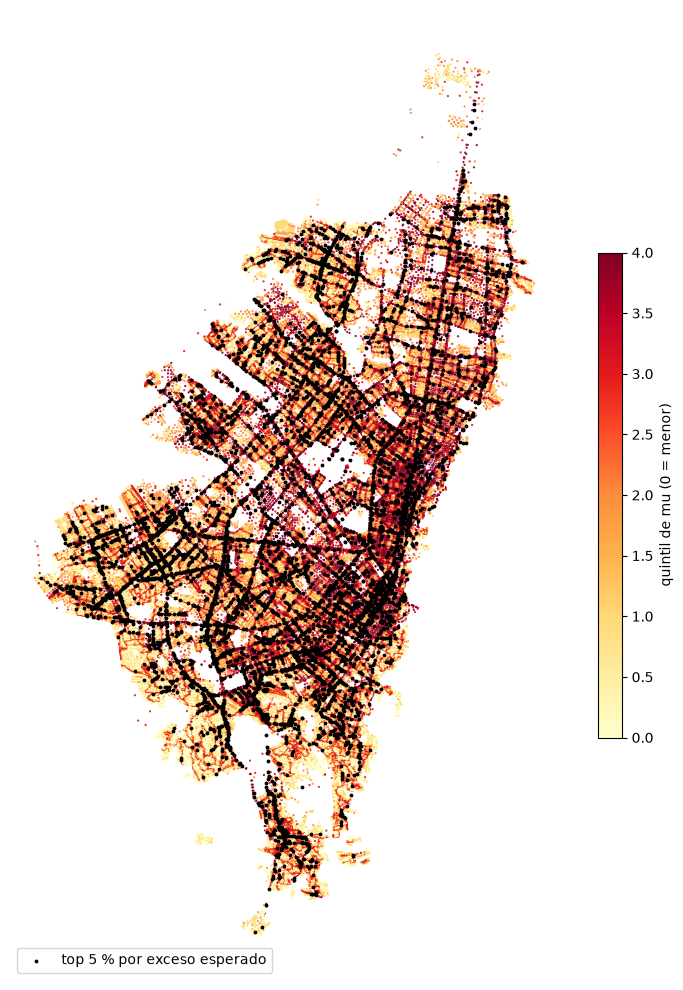

In [14]:
## Mapa de la superficie de riesgo predicho (A) por quintiles de mu, con el top-N de referencia del exceso esperado resaltado
fig, ax = plt.subplots(figsize=(8, 10))
quint = pd.qcut(pri['mu_A'], 5, labels=False, duplicates='drop')
sc = ax.scatter(pri[COL_X], pri[COL_Y], c=quint, s=0.3, cmap='YlOrRd', rasterized=True)
ref = pri.loc[ids_ref]
ax.scatter(ref[COL_X], ref[COL_Y], s=3, c='black', label=f'top {P_REF} % por exceso esperado')
ax.set_aspect('equal')
ax.set_axis_off()
ax.legend(loc='lower left')
plt.colorbar(sc, ax=ax, shrink=0.5, label='quintil de mu (0 = menor)')
plt.tight_layout()
plt.savefig(f'{CARPETA_OBJ3}/mapa_mu_predicha.png', dpi=200)
plt.show()

In [15]:
## Diagnóstico del decil de longitud con Pearson alto: segmentos que más aportan al Pearson al cuadrado
pri['mu_bruta'] = mu_bruta
pri['pearson2'] = pearson2    # definido en la celda de verificación de alpha, con mu sin calibrar
dec_cod = pd.qcut(pri['long_m'], 10, labels=False, duplicates='drop')
d7 = pri[dec_cod == 6].sort_values('pearson2', ascending=False)
print(d7[['long_m', 'n_obs', 'mu_bruta', 'pearson2']].head(10).round(2).to_string())
print('Aporte de los 20 mayores al promedio del decil:', round(d7['pearson2'].head(20).sum() / len(d7), 3), '| promedio del decil:', round(d7['pearson2'].mean(), 3))

## Sensibilidad de alpha: alpha por decil de longitud (máxima verosimilitud con mu fija) y efecto sobre los conjuntos priorizados de B y C
from scipy.optimize import minimize_scalar
from scipy.special import gammaln


def nll_alpha(log_a, y, mu):
    r = 1 / np.exp(log_a)    # r = 1/alpha
    ll = gammaln(y + r) - gammaln(r) - gammaln(y + 1) + r * np.log(r / (r + mu)) + y * np.log(mu / (r + mu))    # log-verosimilitud BN tipo 2
    return -ll.sum()


alpha_dec = {}
for g in sorted(dec_cod.unique()):
    m = (dec_cod == g).to_numpy()
    res = minimize_scalar(nll_alpha, bounds=(np.log(1e-4), np.log(50)), args=(n_obs[m], mu_bruta[m]), method='bounded')
    alpha_dec[int(g) + 1] = float(np.exp(res.x))
print('alpha por decil de longitud:', {k: round(v, 3) for k, v in alpha_dec.items()})

a_seg = dec_cod.map({g - 1: a for g, a in alpha_dec.items()}).to_numpy()
w_g = 1 / (1 + a_seg * pri['mu_A'].to_numpy())
nesp_g = pd.Series(w_g * pri['mu_A'].to_numpy() + (1 - w_g) * pri['n_obs'].to_numpy(), index=pri.index)
exc_g = nesp_g - pri['mu_A']

filas = []
for p in TOP_PCT:
    n = int(round(N_RED * p / 100))
    for nombre, serie in [('B_esperada_EB', nesp_g), ('C_exceso', exc_g)]:
        n_e = min(n, n_pos) if nombre == 'C_exceso' else n    # C se limita a los segmentos con exceso positivo
        nuevo = set(serie.nlargest(n_e).index)
        base = top[(nombre, p)]
        filas.append(dict(escenario=nombre, top_pct=p, jaccard_alpha_constante_vs_por_decil=len(nuevo & base) / len(nuevo | base)))
print(pd.DataFrame(filas).round(3).to_string(index=False))

        long_m  n_obs  mu_bruta  pearson2
43288    65.61   52.0      0.12  16270.07
13421    64.20    4.0      0.05    269.68
16462    59.26    5.0      0.12    148.61
130139   69.32   11.0      0.40    129.64
39291    67.67    2.0      0.03    120.35
9945     64.57    2.0      0.04     95.53
9908     68.34    2.0      0.04     92.66
121023   65.92    2.0      0.04     91.17
15094    63.00    2.0      0.04     88.05
18205    70.87    6.0      0.24     80.68
Aporte de los 20 mayores al promedio del decil: 1.371 | promedio del decil: 2.098
alpha por decil de longitud: {1: 5.786, 2: 3.711, 3: 2.426, 4: 2.191, 5: 2.825, 6: 2.824, 7: 3.126, 8: 2.522, 9: 2.279, 10: 2.723}
    escenario  top_pct  jaccard_alpha_constante_vs_por_decil
B_esperada_EB        1                                 0.921
     C_exceso        1                                 0.921
B_esperada_EB        5                                 0.922
     C_exceso        5                                 0.781
B_esperada_EB       

### 12. Segundo eje descriptivo: cobertura peatonal de los priorizados

La razón de cobertura ya es covariable del modelo y, por tanto, está dentro de μ: no se suma al puntaje de priorización (se contaría dos veces). Se usa solo para clasificar a los segmentos priorizados.

- Es **cobertura**, no estado: no dice en qué condición está el andén ni qué tipo de infraestructura falta (mezcla andenes y otras infraestructuras peatonales).

In [16]:
## Bandas de cobertura (las mismas del análisis de tramos del modelo) y su distribución en la red y en el top-N de referencia de cada escenario
COL_COB = 'ratio_cobertura_peatonal'
cob = df_unificado[COL_COB].to_numpy(float)
print(f'Cobertura: min {cob.min():.3f} | max {cob.max():.3f} | segmentos con cobertura > 1: {(cob > 1).sum()}')

ETIQ_COB = ['0-5 %', '5-25 %', '25-50 %', '50-99 %', '100 %']
pri['cob'] = cob
pri['banda_cob'] = pd.Categorical(np.select([cob >= 1 - 1e-9, cob >= 0.5, cob >= 0.25, cob >= 0.05],
                                            ['100 %', '50-99 %', '25-50 %', '5-25 %'], default='0-5 %'),
                                  categories=ETIQ_COB, ordered=True)

dist_cob = pd.DataFrame({'red': pri['banda_cob'].value_counts(normalize=True)})
for nombre in ESCENARIOS:
    dist_cob[nombre] = pri.loc[list(top[(nombre, P_REF)]), 'banda_cob'].value_counts(normalize=True)
dist_cob = (dist_cob.reindex(ETIQ_COB).fillna(0) * 100).round(1)
print(f'% de segmentos por banda de cobertura (top {P_REF} % de cada escenario)')
print(dist_cob.to_string())

Cobertura: min 0.000 | max 1.000 | segmentos con cobertura > 1: 0
% de segmentos por banda de cobertura (top 5 % de cada escenario)
            red  A_predicha  B_esperada_EB  C_exceso
banda_cob                                           
0-5 %      43.8         0.0            0.3       1.2
5-25 %     10.7         0.0            1.2       3.1
25-50 %     8.1         0.0            0.6       1.6
50-99 %     2.0         0.9            1.0       1.1
100 %      35.4        99.0           96.8      92.9


In [17]:
## Déficit de cobertura con tres definiciones: absoluto bajo (< 5 %), absoluto amplio (< 25 %) y relativo al grupo (percentil <= 25 dentro del grupo)
COL_GRUPO = next(c for c in ['tipo_via', 'localidad', 'MVI_VELREG'] if c in df_unificado.columns)    # el grupo más fino disponible; MVI_VELREG es solo un sustituto del tipo de vía
pri['grupo_def'] = df_unificado[COL_GRUPO]
pct_grupo = pri.groupby('grupo_def')['cob'].rank(pct=True)    # los empates reciben el rango promedio del grupo

defs = {'absoluto < 5 %': pri['cob'] < 0.05, 'absoluto < 25 %': pri['cob'] < 0.25, f'relativo ({COL_GRUPO}) p25': pct_grupo <= 0.25}
filas = []
for nombre_def, marca in defs.items():
    fila = {'definicion': nombre_def, 'red_%': 100 * marca.mean()}
    for nombre in ESCENARIOS:
        fila[nombre + '_%'] = 100 * marca.loc[list(top[(nombre, P_REF)])].mean()
    filas.append(fila)
tabla_deficit = pd.DataFrame(filas)
print(f'% de segmentos con déficit de cobertura en el top {P_REF} % (grupo de la definición relativa: {COL_GRUPO})')
print(tabla_deficit.round(1).to_string(index=False))

% de segmentos con déficit de cobertura en el top 5 % (grupo de la definición relativa: MVI_VELREG)
               definicion  red_%  A_predicha_%  B_esperada_EB_%  C_exceso_%
           absoluto < 5 %   43.8           0.0              0.3         1.2
          absoluto < 25 %   54.5           0.0              1.5         4.3
relativo (MVI_VELREG) p25    1.4           0.9              0.9         0.8


In [18]:
## Cruce en el top-N de referencia por exceso esperado: banda de cobertura por velocidad reglamentaria (n de segmentos y % de fallecidos si existe)
ref_top = pri.loc[ids_ref].assign(vel_reg=df_unificado.loc[ids_ref, 'MVI_VELREG'])
cruce_n = pd.crosstab(ref_top['banda_cob'], ref_top['vel_reg'])
print('Segmentos por banda de cobertura y velocidad reglamentaria')
print(cruce_n.to_string())

if COL_MUERTOS in pri.columns:
    g = ref_top.groupby(['banda_cob', 'vel_reg'], observed=True)[[COL_MUERTOS, 'n_obs']].sum()
    g['pct_fallecidos'] = 100 * g[COL_MUERTOS] / g['n_obs'].where(g['n_obs'] > 0)    # evita dividir por cero en celdas sin siniestros
    print('% de fallecidos por banda de cobertura y velocidad')
    print(g['pct_fallecidos'].unstack().round(1).to_string())

Segmentos por banda de cobertura y velocidad reglamentaria
vel_reg      30    60
banda_cob            
0-5 %        73     9
5-25 %      198     6
25-50 %      99     6
50-99 %      41    34
100 %      3021  3098
% de fallecidos por banda de cobertura y velocidad
vel_reg     30    60
banda_cob           
0-5 %      2.2   0.0
5-25 %     5.5   7.7
25-50 %    4.6   7.7
50-99 %    3.9  19.8
100 %      5.2   9.4


In [19]:
## Exportación de las tablas y del ranking completo para la sección 4.3
tabla_sin.to_csv(f'{CARPETA_OBJ3}/pct_sin_siniestros.csv', index=False)
tabla_coinc.to_csv(f'{CARPETA_OBJ3}/coincidencia.csv', index=False)
tabla_sev.to_csv(f'{CARPETA_OBJ3}/severidad_top.csv', index=False)
tabla_sens_km.to_csv(f'{CARPETA_OBJ3}/sensibilidad_por_km.csv', index=False)
spearman.to_csv(f'{CARPETA_OBJ3}/spearman_red_completa.csv')
spearman_con.to_csv(f'{CARPETA_OBJ3}/spearman_con_siniestros.csv')
dist_cob.to_csv(f'{CARPETA_OBJ3}/cobertura_bandas.csv')
tabla_deficit.to_csv(f'{CARPETA_OBJ3}/cobertura_deficit.csv', index=False)
cruce_n.to_csv(f'{CARPETA_OBJ3}/cobertura_x_velocidad.csv')
pri.to_csv(f'{CARPETA_OBJ3}/priorizacion_segmentos.csv', index_label='pos')
print('Archivos en', CARPETA_OBJ3, ':', sorted(os.listdir(CARPETA_OBJ3)))

Archivos en Data/processed/obj3 : ['cobertura_bandas.csv', 'cobertura_deficit.csv', 'cobertura_x_velocidad.csv', 'coincidencia.csv', 'mapa_mu_predicha.png', 'pct_sin_siniestros.csv', 'priorizacion_segmentos.csv', 'sensibilidad_por_km.csv', 'severidad_top.csv', 'spearman_con_siniestros.csv', 'spearman_red_completa.csv']


In [20]:
## Consistencia del indicador de ceros en el escenario A: probabilidad de cero que asigna la propia BN frente al % observado de segmentos sin siniestros en cada top-N
p0 = (1 + alpha * pri['mu_A']) ** (-1 / alpha)    # P(y = 0) de una BN tipo 2 con media mu
filas = []
for p in TOP_PCT:
    idx = list(top[('A_predicha', p)])
    filas.append(dict(top_pct=p, mu_medio=pri.loc[idx, 'mu_A'].mean(), p0_esperado_pct=100 * p0.loc[idx].mean(),
                      pct_sin_siniestros_obs=100 * pri.loc[idx, 'n_obs'].eq(0).mean()))
tabla_p0 = pd.DataFrame(filas)
print(tabla_p0.round(2).to_string(index=False))

## Diagnóstico de la definición relativa: por grupo, tamaño, % con cobertura exactamente 0 y % marcado como déficit relativo
marca_rel = defs[f'relativo ({COL_GRUPO}) p25']
diag = pd.DataFrame({'grupo': pri['grupo_def'], 'cero': pri['cob'] == 0, 'marcado': marca_rel}).groupby('grupo').agg(n=('cero', 'size'), pct_cero=('cero', 'mean'), pct_marcado=('marcado', 'mean'))
print(diag.assign(pct_cero=diag['pct_cero'] * 100, pct_marcado=diag['pct_marcado'] * 100).round(1).to_string())

 top_pct  mu_medio  p0_esperado_pct  pct_sin_siniestros_obs
       1      1.12            60.70                   57.40
       5      0.76            67.22                   66.48
      10      0.60            71.10                   70.55
            n  pct_cero  pct_marcado
grupo                               
30     110738      50.9          0.0
60      20966       5.5          8.9


In [21]:
## Segmentos con conteos extremos: posible artefacto de asignación (empates en intersecciones o coordenadas repetidas)
pri['mu_bruta'] = mu_bruta
ext = pri.sort_values('n_obs', ascending=False).head(20)[['n_obs', 'mu_bruta', 'long_m', COL_X, COL_Y, 'rank_C_exceso']].copy()
ext['n_obs_sobre_mu'] = ext['n_obs'] / ext['mu_bruta']
print(ext.round(2).to_string())
print('Siniestros en los 20 segmentos con más conteo:', int(ext['n_obs'].sum()), 'de', int(pri['n_obs'].sum()))
print('Segmentos con 10 o más siniestros:', int((pri['n_obs'] >= 10).sum()))

        n_obs  mu_bruta  long_m         x_m         y_m  rank_C_exceso  n_obs_sobre_mu
43288    52.0      0.12   65.61   991506.81  1004000.41            1.0          423.55
81822    17.0      0.72  124.22  1000203.54  1000834.85            2.0           23.71
51476    17.0      0.21    6.97   995756.70  1004816.98           30.0           79.81
81793    16.0      0.51   47.42  1000091.42  1000681.57            4.0           31.40
83679    15.0      0.58  147.71  1001056.91  1002555.47            7.0           26.03
80219    15.0      1.10   88.15   999337.68   999490.99            3.0           13.62
82256    15.0      0.46   79.77  1000297.20  1001571.47           11.0           32.78
20069    14.0      0.73   65.68   995368.12   997752.48            6.0           19.13
74709    14.0      0.48   21.90   998400.91   995353.30           13.0           29.27
82259    14.0      0.77  118.34  1000290.41  1001644.53            5.0           18.15
81210    13.0      0.18    6.80  1000397.28

In [22]:
## Verificación de los conteos extremos: coordenadas repetidas, puntos por defecto, duplicados y sensibilidad del orden de C


RUTA_SEG = 'Data/processed/segmentos_unificado.gpkg'        # mismos segmentos que el CSV, con geometría y seg_id
RUTA_SIN = 'Data/processed/siniestros_procesados.gpkg'      # un registro por peatón afectado
UMBRAL_SIN_M = 30                                           # el mismo umbral de la unión

seg = gpd.read_file(RUTA_SEG)
assert len(seg) == len(df_unificado) and np.array_equal(seg['n_siniestros'].to_numpy(float), n_obs), 'El .gpkg no tiene el mismo orden que el CSV'
reg = gpd.read_file(RUTA_SIN).reset_index(drop=True)
reg['_id'] = reg.index
reg['xy'] = reg['LATITUD'].round(6).astype(str) + '|' + reg['LONGITUD'].round(6).astype(str)

## (a) Coordenadas repetidas y posibles puntos por defecto, sobre todos los registros con coordenadas
con_xy = reg.dropna(subset=['LATITUD', 'LONGITUD'])
cuenta = con_xy['xy'].value_counts()
dirs = con_xy.groupby('xy')['DIRECCION'].nunique()
print(f"Registros con coordenadas: {len(con_xy):,} | coordenadas distintas: {len(cuenta):,} | "
      f"registros que comparten coordenada: {int((con_xy['xy'].map(cuenta) > 1).sum()):,}")
print(f"Máximo de registros en una coordenada: {cuenta.max()} | máximo de direcciones distintas en una coordenada: {dirs.max()}")
d_plaza = np.hypot((con_xy['LATITUD'] - 4.598) * 111000, (con_xy['LONGITUD'] + 74.076) * 111000 * np.cos(np.radians(4.6)))
print('Registros a menos de 20 m de la Plaza de Bolívar:', int((d_plaza < 20).sum()))

## (b) Asignación a segmentos con la misma regla de la unión (vecino más próximo a 30 m; empate: menor seg_id)
par = gpd.sjoin_nearest(reg, seg[['seg_id', 'geometry']], max_distance=UMBRAL_SIN_M, distance_col='dist_m').sort_values(['_id', 'seg_id'])
print('Pares sobrantes por empate de distancia:', len(par) - par['_id'].nunique())
par = par.drop_duplicates('_id', keep='first')
par['pos'] = par['seg_id'].map(pd.Series(np.arange(len(seg)), index=seg['seg_id']))

## (c) Inspección de los veinte primeros del escenario C
top20 = pri.sort_values('rank_C_exceso').index[:20]
filas = []
for pos in top20:
    q = par[par['pos'] == pos]
    v = q['xy'].value_counts()
    acc = q.drop_duplicates('CODIGO_ACCIDENTE')
    filas.append(dict(puesto_C=int(pri.loc[pos, 'rank_C_exceso']), long_m=round(pri.loc[pos, 'long_m'], 1),
                      siniestros=int(pri.loc[pos, 'n_obs']), predichos=round(pri.loc[pos, 'mu_A'], 2),
                      registros=len(q), max_en_una_coord=int(v.iloc[0]),
                      direccion=q.loc[q['xy'] == v.index[0], 'DIRECCION'].value_counts().index[0],
                      siniestros_misma_coord_fecha_hora=int(acc.duplicated(['xy', 'FECHA_OCURRENCIA_ACC', 'HORA'], keep=False).sum())))
tabla_top20 = pd.DataFrame(filas)
print(tabla_top20.to_string(index=False))

## (d) Sensibilidad: mismo alpha, mismos pesos y mismo mu calibrado; solo cambia el conteo observado
alts = {
    'T1_una_coordenada_por_segmento_y_anio': par.drop_duplicates(['pos', 'xy', 'ANO_OCURRENCIA_ACC'])
                                                .groupby('pos')['CODIGO_ACCIDENTE'].nunique().reindex(pri.index).fillna(0),
    'T2_tope_10_por_segmento': pri['n_obs'].clip(upper=10),
}

def conjunto_c(n_alt, p):
    ex = (1 - pri['w_eb']) * (n_alt - pri['mu_A'])
    n = min(int(round(N_RED * p / 100)), int((ex > 0).sum()))
    r = ex.rank(ascending=False, method='first')
    return set(r.index[r <= n]), r

sens = []
for nombre, n_alt in alts.items():
    for p in TOP_PCT:
        nuevo, _ = conjunto_c(n_alt, p)
        base = top[('C_exceso', p)]
        sens.append(dict(tratamiento=nombre, top_pct=p, siniestros=n_alt.sum(), jaccard=len(base & nuevo) / len(base | nuevo)))
    _, r_alt = conjunto_c(n_alt, P_REF)
    print(f"{nombre}: primer segmento original pasa al puesto {int(r_alt.loc[top20[0]])}; "
          f"los 20 originales quedan en los puestos {sorted(r_alt.loc[top20].astype(int))}")
tabla_sens_extremos = pd.DataFrame(sens)
print(tabla_sens_extremos.round(3).to_string(index=False))

tabla_top20.to_csv(f'{CARPETA_OBJ3}/conteos_extremos_top20.csv', index=False)
tabla_sens_extremos.to_csv(f'{CARPETA_OBJ3}/conteos_extremos_sensibilidad.csv', index=False)

Registros con coordenadas: 21,893 | coordenadas distintas: 17,712 | registros que comparten coordenada: 6,810
Máximo de registros en una coordenada: 41 | máximo de direcciones distintas en una coordenada: 5
Registros a menos de 20 m de la Plaza de Bolívar: 0
Pares sobrantes por empate de distancia: 41
 puesto_C  long_m  siniestros  predichos  registros  max_en_una_coord                      direccion  siniestros_misma_coord_fecha_hora
        1    65.6          52       0.12         54                41                  KR 80-CL 2 51                                  0
        2   124.2          17       0.71         19                10                 KR 10-CL 15 02                                  0
        3    88.1          15       1.09         15                 9                   KR 10-CL 2 2                                  0
        4    47.4          16       0.50         16                13                 KR 10-CL 13 02                                  0
        5   118.3

In [23]:
## Geometría de los segmentos para los mapas: con RUTA_MALLA = None se dibujan los centroides (x_m, y_m); si se da la capa de la MVI se dibujan las líneas reales
RUTA_MALLA = None    # ejemplo: 'Data/processed/mvi_segmentos.gpkg' (la capa de la que salió el conjunto unificado, en EPSG:3116)
geo = None
if RUTA_MALLA is not None:
    from scipy.spatial import cKDTree
    malla = gpd.read_file(RUTA_MALLA)
    cen = malla.geometry.centroid
    dist_cen, pos_cen = cKDTree(np.c_[cen.x, cen.y]).query(np.c_[pri[COL_X], pri[COL_Y]])    # centroide de la capa más cercano a cada segmento del modelo
    assert dist_cen.max() < 1, f'La capa no corresponde al conjunto del modelo (distancia máxima al centroide: {dist_cen.max():.1f} m)'
    assert len(set(pos_cen)) == len(pos_cen), 'Dos segmentos del modelo caen en el mismo centroide de la capa'
    geo = malla.geometry.iloc[pos_cen].set_axis(pri.index)    # mismo índice que pri
print('Mapas con', 'líneas' if geo is not None else 'centroides')

Mapas con centroides


In [24]:
## Segmentos de riesgo estimado alto sin siniestros registrados (escenario A): resumen por top-N y lista ordenada del top de referencia
filas = []
for p in TOP_PCT:
    sel = pri.loc[list(top[('A_predicha', p)])]
    sel0 = sel[sel['n_obs'] == 0]
    filas.append(dict(top_pct=p, n_top=len(sel), n_sin_siniestros=len(sel0), pct_sin_siniestros=100 * len(sel0) / len(sel),
                      km_sin_siniestros=sel0['long_m'].sum() / 1000, mu_medio_sin=sel0['mu_A'].mean(),
                      mu_medio_con=sel.loc[sel['n_obs'] > 0, 'mu_A'].mean()))
tabla_A_sin = pd.DataFrame(filas)
print(tabla_A_sin.round(2).to_string(index=False))

pri['A_alto_sin_sin'] = pri.index.isin(top[('A_predicha', P_REF)]) & pri['n_obs'].eq(0)
lista_A_sin = pri.loc[pri['A_alto_sin_sin']].sort_values('mu_A', ascending=False)
print(f'Lista del top {P_REF} %: {len(lista_A_sin)} segmentos, {lista_A_sin["long_m"].sum() / 1000:.1f} km')

 top_pct  n_top  n_sin_siniestros  pct_sin_siniestros  km_sin_siniestros  mu_medio_sin  mu_medio_con
       1   1317               756               57.40             118.57          1.11          1.15
       5   6585              4378               66.48             517.65          0.74          0.79
      10  13170              9292               70.55             952.04          0.59          0.65
Lista del top 5 %: 4378 segmentos, 517.7 km


c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


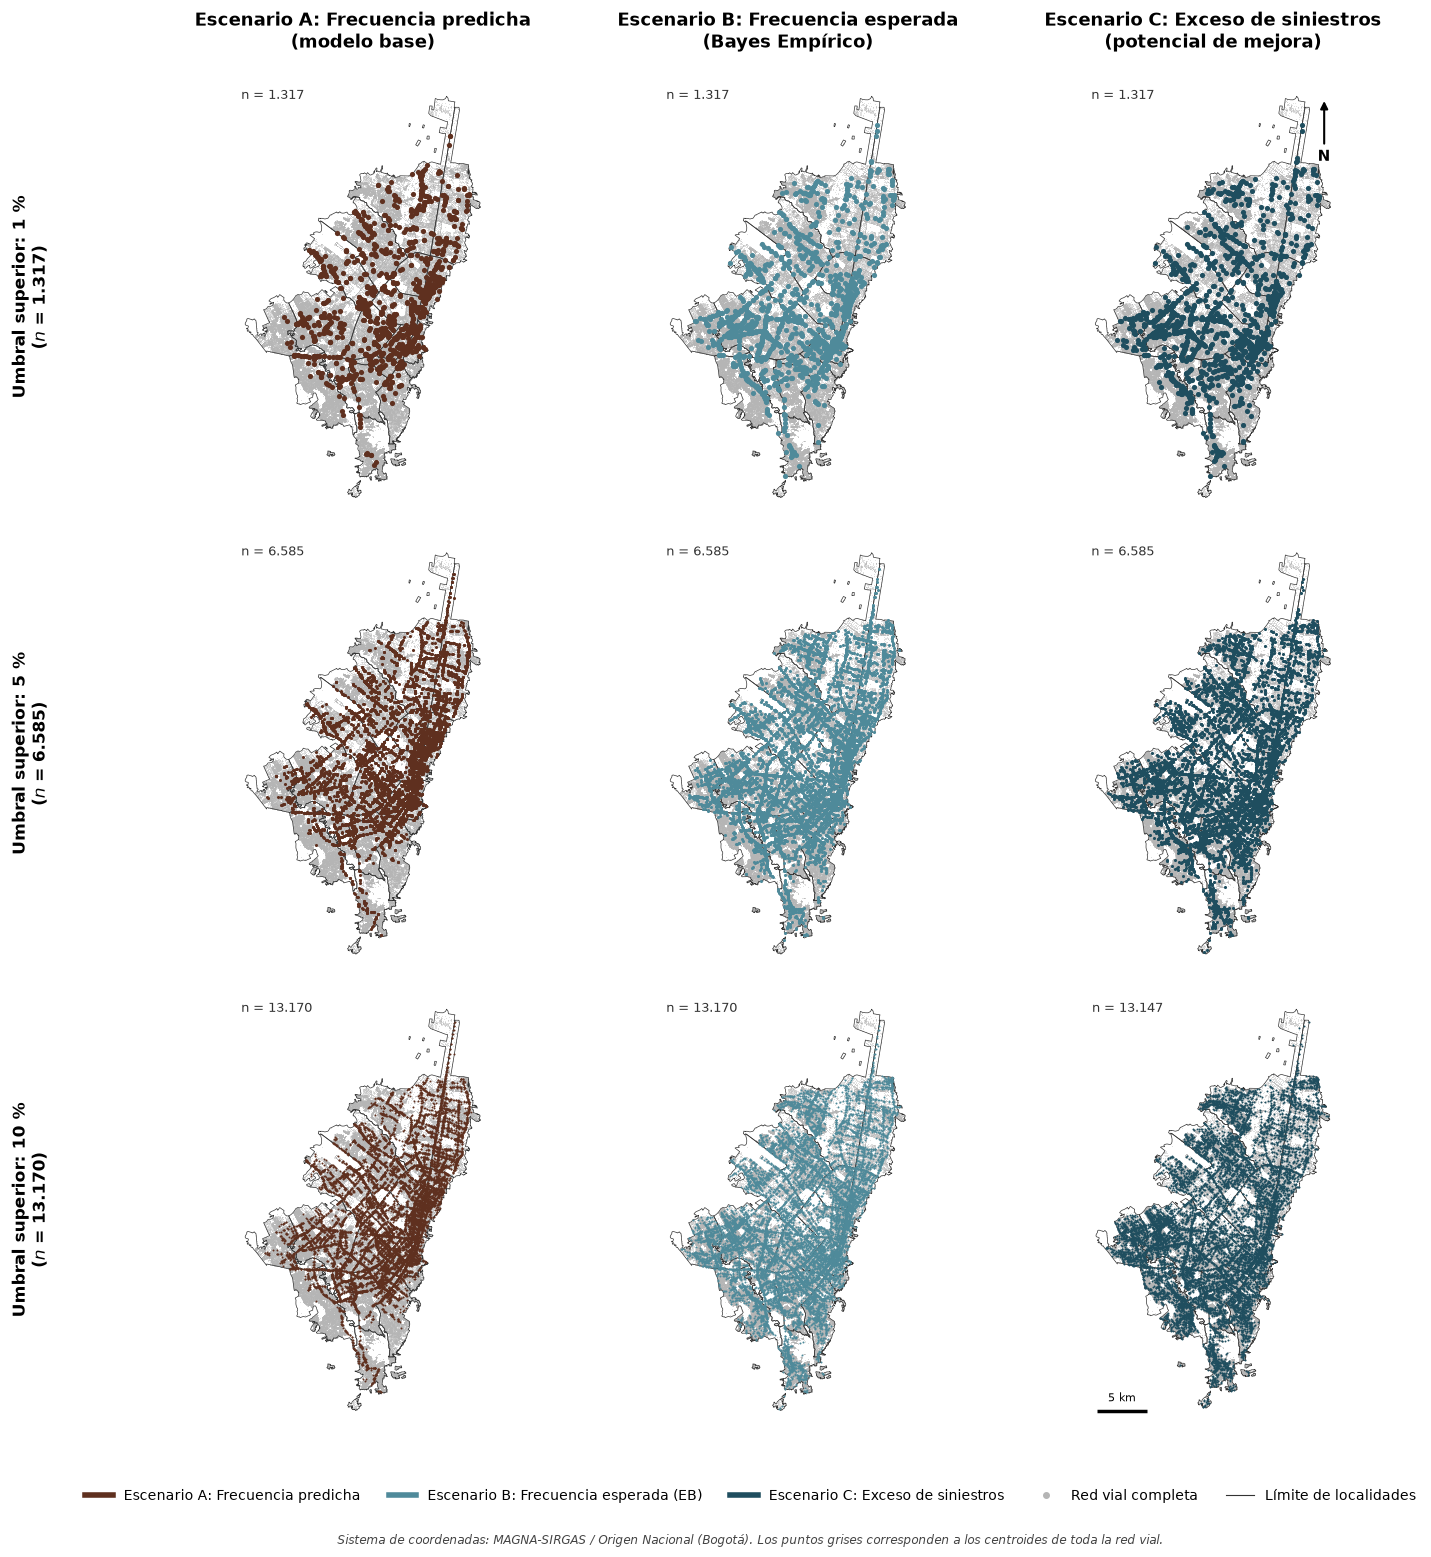

In [25]:
## --- Perímetro del POT: define el encuadre y el contorno fijo ---
perimetro = gpd.read_file("Data/raw/perimetrourbano (1).gpkg") # ajusta la ruta
if perimetro.crs is None:
    perimetro = perimetro.set_crs(4326)       # solo si el archivo no trae CRS
perimetro = perimetro.to_crs(3116)            # mismo sistema que tus datos (metros)

# Localidades recortadas al perímetro (líneas internas, más tenues)
localidades = gpd.read_file("Data/raw/Loca.shp")
if localidades.crs is None:
    localidades = localidades.set_crs(4326)
localidades = gpd.clip(localidades.to_crs(3116), perimetro)

# Encuadre: bounds del perímetro + 3 % de margen
minx, miny, maxx, maxy = perimetro.total_bounds
mx, my = 0.03 * (maxx - minx), 0.03 * (maxy - miny)
XLIM = (minx - mx, maxx + mx)
YLIM = (miny - my, maxy + my)

## --- Etiquetas institucionales ---
TITULOS_COL = {
    'A_predicha':    'Escenario A: Frecuencia predicha\n(modelo base)',
    'B_esperada_EB': 'Escenario B: Frecuencia esperada\n(Bayes Empírico)',
    'C_exceso':      'Escenario C: Exceso de siniestros\n(potencial de mejora)',
}
LEYENDA_COL = {
    'A_predicha':    'Escenario A: Frecuencia predicha',
    'B_esperada_EB': 'Escenario B: Frecuencia esperada (EB)',
    'C_exceso':      'Escenario C: Exceso de siniestros',
}

def miles(n):                      # 1,317 -> 1.317 (formato español)
    return f'{n:,}'.replace(',', '.')

## --- Colores: base + versión más oscura para el 1 % (mayor contraste) ---
# Paleta del documento: café (#5F301F) y azul petróleo (#1F4E5F), con un tono intermedio para B
COLORES = {'A_predicha': '#5F301F', 'B_esperada_EB': '#4F8A9A', 'C_exceso': '#1F4E5F'}
COLORES_1PCT = COLORES    # mismo tono en los tres umbrales

## --- Grosor / tamaño según el umbral: más grueso en 1 %, más fino en 10 % ---
ESTILO = {1: dict(lw=2.2, s=14), 5: dict(lw=1.2, s=5), 10: dict(lw=0.6, s=2)}

def estilo(p):
    return ESTILO.get(p, dict(lw=1.0, s=4))


def fondo(ax):
    # Red completa (centroides) en gris más oscuro que antes
    ax.scatter(pri[COL_X], pri[COL_Y], s=0.15, c='#b5b5b5', linewidths=0,
               rasterized=True, zorder=1)
    # Contorno fijo de la ciudad (localidades)
    localidades.boundary.plot(ax=ax, color='#333333', linewidth=0.5, zorder=2)
    ax.set_aspect('equal')
    ax.set_axis_off()


def dibujar(ax, ids, color, p):
    ids = list(ids)
    est = estilo(p)
    if geo is not None:
        geo.loc[ids].plot(ax=ax, color=color, linewidth=est['lw'], zorder=3)
    else:
        ax.scatter(pri.loc[ids, COL_X], pri.loc[ids, COL_Y], s=est['s'],
                   c=color, linewidths=0, zorder=3)


def barra_escala(ax, largo_m=5000):
    """Barra de escala en metros (requiere CRS proyectado, p. ej. EPSG:3116)."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    xi = x0 + 0.05 * (x1 - x0)
    yi = y0 + 0.04 * (y1 - y0)
    ax.plot([xi, xi + largo_m], [yi, yi], color='black', lw=2.5,
            solid_capstyle='butt', zorder=5)
    ax.text(xi + largo_m / 2, yi + 0.015 * (y1 - y0), f'{largo_m // 1000} km',
            ha='center', va='bottom', fontsize=8, zorder=5)


def flecha_norte(ax):
    ax.annotate('N', xy=(0.93, 0.95), xytext=(0.93, 0.80), xycoords='axes fraction',
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                arrowprops=dict(arrowstyle='-|>', color='black', lw=1.5))


fig, axes = plt.subplots(len(TOP_PCT), len(ESCENARIOS),
                         figsize=(15, 5.2 * len(TOP_PCT)), squeeze=False)

for i, p in enumerate(TOP_PCT):
    for j, nombre in enumerate(ESCENARIOS):
        ax = axes[i, j]
        color = COLORES_1PCT[nombre] if p == 1 else COLORES[nombre]
        fondo(ax)
        dibujar(ax, top[(nombre, p)], color, p)

        # Título de columna solo en la fila superior (jerarquía limpia)
        if i == 0:
            ax.set_title(TITULOS_COL[nombre], fontsize=13, fontweight='bold', pad=10)

        # Subtítulo discreto con n de cada panel
        ax.text(0.03, 0.97, f'n = {miles(len(top[(nombre, p)]))}',
                transform=ax.transAxes, ha='left', va='top', fontsize=9,
                color='#333333')

# Elementos cartográficos: una sola vez, en el último mapa
barra_escala(axes[-1, -1], largo_m=5000)
flecha_norte(axes[0, -1])

# Leyenda lateral/unificada de colores
handles = [Line2D([0], [0], color=COLORES[n], lw=4, label=LEYENDA_COL[n]) for n in ESCENARIOS]
handles.append(Line2D([0], [0], color='#b5b5b5', marker='o', lw=0, markersize=4,
                      label='Red vial completa'))
handles.append(Line2D([0], [0], color='#333333', lw=0.8, label='Límite de localidades'))
fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, 0.025))

plt.tight_layout(rect=[0.05, 0.07, 1, 1])

# Etiquetas de fila (umbral de selección), ubicadas según la posición real de cada fila
# Etiquetas de fila (umbral de selección), ubicadas según la posición real de cada fila
nombres = list(ESCENARIOS)          # claves del diccionario, en orden

for i, p in enumerate(TOP_PCT):
    pos = axes[i, 0].get_position()
    n = len(top[(nombres[0], p)])
    fig.text(0.02, pos.y0 + pos.height / 2,
             f'Umbral superior: {p} %\n($n$ = {miles(n)})',
             rotation=90, ha='center', va='center', fontsize=12, fontweight='bold')

# Nota al pie con sistema de referencia
fig.text(0.5, 0.005,
         'Sistema de coordenadas: MAGNA-SIRGAS / Origen Nacional (Bogotá). '
         'Los puntos grises corresponden a los centroides de toda la red vial.',
         ha='center', va='bottom', fontsize=8.5, style='italic', color='#444444')

plt.savefig(f'{CARPETA_OBJ3}/mapa_priorizados_escenarios.png', dpi=200, bbox_inches='tight')
plt.show()

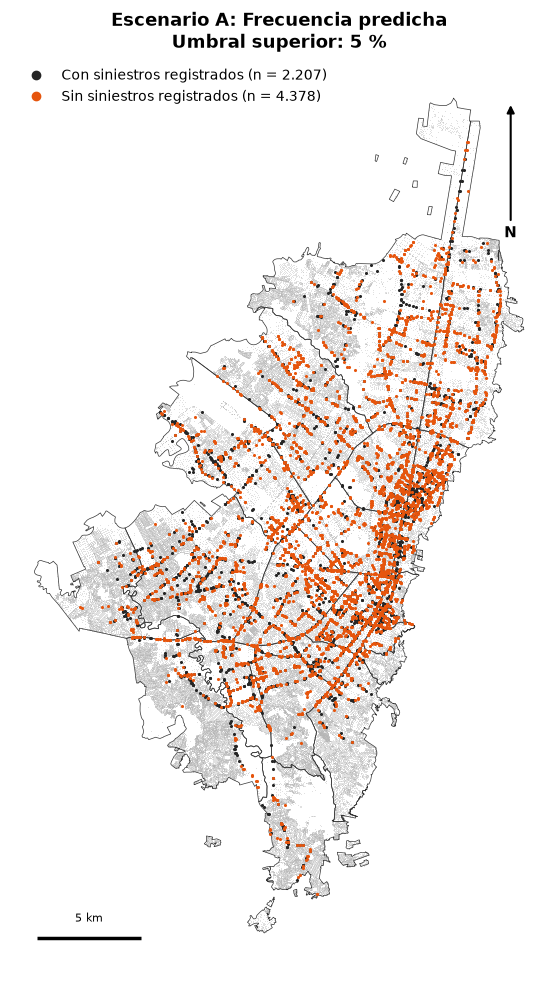

In [26]:
selA = pri.loc[list(top[('A_predicha', P_REF)])]
con = selA.index[selA['n_obs'] > 0]
sin = selA.index[selA['n_obs'] == 0]

fig, ax = plt.subplots(figsize=(8, 10))
fondo(ax)
dibujar(ax, con, '#252525', P_REF)
dibujar(ax, sin, '#e6550d', P_REF)

barra_escala(ax, largo_m=5000)
flecha_norte(ax)

ax.legend(handles=[Line2D([], [], color='#252525', marker='o', ls='',
                          label=f'Con siniestros registrados (n = {miles(len(con))})'),
                   Line2D([], [], color='#e6550d', marker='o', ls='',
                          label=f'Sin siniestros registrados (n = {miles(len(sin))})')],
          loc='upper left', frameon=False)
ax.set_title(f'Escenario A: Frecuencia predicha\nUmbral superior: {P_REF} %',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CARPETA_OBJ3}/mapa_A_con_y_sin_siniestros.png', dpi=200)
plt.show()

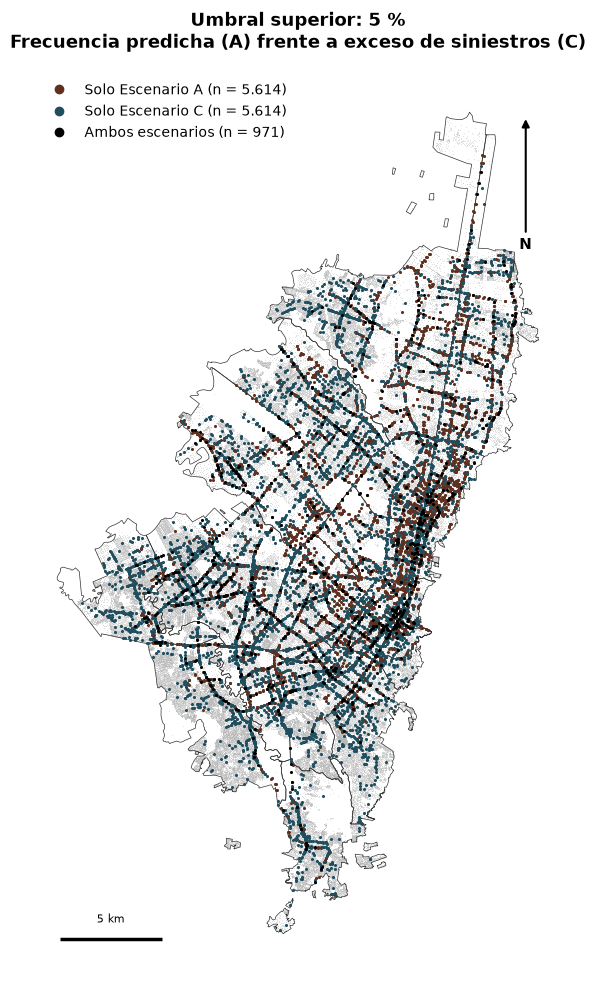

In [27]:
## Mapa de la diferencia entre A y C en el top de referencia: solo A, solo C y ambos
a_ref, c_ref = top[('A_predicha', P_REF)], top[('C_exceso', P_REF)]
solo_a, solo_c, ambos = a_ref - c_ref, c_ref - a_ref, a_ref & c_ref

fig, ax = plt.subplots(figsize=(8, 10))
fondo(ax)
dibujar(ax, solo_a, COLORES['A_predicha'], P_REF)
dibujar(ax, solo_c, COLORES['C_exceso'], P_REF)
dibujar(ax, ambos, 'black', P_REF)

barra_escala(ax, largo_m=5000)
flecha_norte(ax)

ax.legend(handles=[
    Line2D([], [], color=COLORES['A_predicha'], marker='o', ls='',
           label=f'Solo Escenario A (n = {miles(len(solo_a))})'),
    Line2D([], [], color=COLORES['C_exceso'], marker='o', ls='',
           label=f'Solo Escenario C (n = {miles(len(solo_c))})'),
    Line2D([], [], color='black', marker='o', ls='',
           label=f'Ambos escenarios (n = {miles(len(ambos))})')],
    loc='upper left', bbox_to_anchor=(0.0, 1.0), frameon=False)

ax.set_title(f'Umbral superior: {P_REF} %\n'
             'Frecuencia predicha (A) frente a exceso de siniestros (C)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CARPETA_OBJ3}/mapa_A_vs_C.png', dpi=200)
plt.show()

In [28]:
## Tabla consolidada por escenario y top-N (tabla de resultados de la sección 4.3) y exportación de lo que faltaba en la celda de exportación anterior
tabla_resumen = (tabla_sin.merge(tabla_sev[['escenario', 'top_pct', 'long_total_km', 'long_mediana_m']], on=['escenario', 'top_pct'])
                 .sort_values(['top_pct', 'escenario']))
print(tabla_resumen.round(3).to_string(index=False))

tabla_resumen.to_csv(f'{CARPETA_OBJ3}/resumen_escenarios.csv', index=False)
tabla_A_sin.to_csv(f'{CARPETA_OBJ3}/A_sin_siniestros_resumen.csv', index=False)
lista_A_sin.to_csv(f'{CARPETA_OBJ3}/A_sin_siniestros_lista.csv', index_label='pos')
tabla_p0.to_csv(f'{CARPETA_OBJ3}/p0_esperado_A.csv', index=False)
comp_dec.to_csv(f'{CARPETA_OBJ3}/composicion_decil_mu.csv')
print(sorted(os.listdir(CARPETA_OBJ3)))

    escenario  top_pct  n_segmentos  valor_corte  pct_sin_siniestros  pct_exceso_positivo  long_total_km  long_mediana_m
   A_predicha        1         1317        0.886              57.403               29.309        219.332         140.121
B_esperada_EB        1         1317        1.569               0.000               99.848        152.868          99.246
     C_exceso        1         1317        0.925               0.000              100.000        130.624          81.661
   A_predicha        5         6585        0.534              66.484               30.858        804.209         104.919
B_esperada_EB        5         6585        0.600               0.000               97.342        613.391          80.292
     C_exceso        5         6585        0.296               0.000              100.000        529.223          67.197
   A_predicha       10        13170        0.381              70.554               28.117       1385.042          91.974
B_esperada_EB       10        13

## 13. Conclusiones

### Del modelo (valores de la ejecución v5; verificar contra las salidas al re-ejecutar)
- **Modelo final:** binomial negativa con log(longitud) como covariable libre, α ≈ 2,83. El ZINB no mejora a la BN en BIC, log-score ni devianza, por lo que la regla declarada conserva la BN.
- **Longitud:** la elasticidad de la frecuencia esperada respecto de la longitud es ≈ 0,50 (IC95 % ≈ 0,46 a 0,55); el offset de coeficiente 1 queda rechazado. La especificación de la longitud se decidió después de ver la sensibilidad y el texto debe declararlo.
- **Desempeño:** moderado. Devianza explicada ≈ 18,8 % (validación aleatoria) y ≈ 18,6 % (bloques de 2 km); casi no cae al predecir en celdas no vistas. El I de Moran de los residuales es ≈ 0,02 y se concentra en distancias cortas.
- **Calibración en S:** el modelo sobreestima los deciles bajos y subestima los intermedios (7 y 8). Conserva el orden de las frecuencias por decil, no los niveles absolutos.
- **Sin exposición peatonal real:** la cobertura peatonal (IRR ≈ 2) actúa como proxy de actividad; calzadas y velocidad pueden reflejar jerarquía vial y no un efecto causal de la infraestructura.

### De la priorización (se cumplen por construcción del Bayes empírico con la BN)
1. El exceso esperado es (1 − w)(y − μ): solo es positivo donde el conteo observado supera a la frecuencia predicha. Un segmento sin siniestros registrados nunca tiene exceso positivo, y su frecuencia esperada con Bayes empírico no supera 1/α.
2. Por eso el % de segmentos sin siniestros es ≈ 0 en el escenario C y bajo en B, y no es un hallazgo empírico. La capacidad de señalar segmentos de riesgo estimado alto sin historial es propia del escenario A; el contraste A frente a C es el que informa.
3. Con α alto el peso de la FDS (w) es bajo en los segmentos de μ alto: B y C dependen sobre todo del conteo observado, y por tanto de la regla de asignación de siniestros a segmentos y del subregistro. Por la misma razón B y C tienden a coincidir entre sí y a separarse de A.
4. La correlación de rangos entre A y C en la red completa es negativa por construcción (entre los segmentos sin siniestros, mayor μ implica exceso más negativo); solo es interpretable entre segmentos con siniestros.
5. A usa solo el orden de μ; B y C usan sus niveles, que están afectados por la calibración en S. La tabla de composición por decil de μ muestra cuánto.
6. La lista indica dónde se espera mayor frecuencia de siniestros peatonales, no dónde la infraestructura es peor. El orden por segmento favorece tramos largos (μ crece con la longitud); la sensibilidad por kilómetro cuantifica ese efecto.
7. La severidad describe a los priorizados y no entra al orden: la priorización trata todos los siniestros como equivalentes y puede subponderar segmentos poco frecuentes pero con alta letalidad (línea futura).
8. La cobertura peatonal ya está dentro de μ (IRR > 1 en la ejecución v5: actúa como proxy de actividad), por lo que no se suma al puntaje; se usa solo para describir a los priorizados. Es cobertura, no estado: no permite afirmar la condición del andén ni qué tipo de infraestructura falta. Como A usa μ, su lista tiende a concentrar cobertura alta; el exceso esperado puede incluir segmentos con baja cobertura donde hay más siniestros que los predichos.
9. Lectura frente a la Política Pública del Peatón (CONPES D.C. 36): la cobertura se lee frente al objetivo 2 (infraestructura continua) y la velocidad reglamentaria frente al objetivo 3 (Sistema Seguro y Visión Cero). La lista no define qué intervención corresponde a cada segmento.

### Limitaciones que hereda la priorización
FDS estimada y aplicada sobre la misma red (predicción dentro de muestra), α constante frente a la longitud, regla de asignación de siniestros a segmentos (empates en intersecciones), subregistro de siniestros, razón de cobertura que mezcla tipos de infraestructura peatonal y no mide estado, infraestructura vigente frente a siniestros 2015–2020, y tamaño del top-N (1 %, 5 % y 10 %) definido por convención y no por presupuesto.

In [29]:
## Conclusiones numéricas de esta ejecución, armadas con los resultados calculados arriba
pct_red_sin = 100 * pri['n_obs'].eq(0).mean()
el = tab.loc['log_long', 'coef'] if ('tab' in globals() and 'log_long' in tab.index) else np.nan

print(f"1. Modelo y calibración: BN con longitud {'libre' if LONGITUD_LIBRE else 'como offset'}, alpha = {alpha:.3f}"
      + (f", elasticidad de la longitud = {el:.3f}" if np.isfinite(el) else '')
      + f". Factor de calibración (observados/predichos) = {cx:.4f}" + (' (aplicado).' if CALIBRAR else ' (no aplicado).'))
print(f"2. Potencial de mejora: {n_pos} segmentos ({100 * n_pos / N_RED:.2f} % de la red) tienen exceso esperado positivo; un top-N mayor que esa cifra incluye segmentos sin potencial de mejora.")

print(f"3. Segmentos sin siniestros registrados (red completa: {pct_red_sin:.2f} %):")
for p in TOP_PCT:
    fila = tabla_sin[tabla_sin['top_pct'] == p].set_index('escenario')['pct_sin_siniestros']
    print(f"   top {p} %: " + ' | '.join(f"{e} = {fila[e]:.2f} %" for e in ESCENARIOS))

print("4. Coincidencia (Jaccard) entre escenarios:")
for p in TOP_PCT:
    print(f"   top {p} %: " + ' | '.join(f"{r.par} = {r.jaccard:.3f}" for r in tabla_coinc[tabla_coinc['top_pct'] == p].itertuples()))
print(f"   Spearman solo con siniestros: A-C = {spearman_con.loc['mu_A', 'exceso_C']:.3f} | A-B = {spearman_con.loc['mu_A', 'N_esp_B']:.3f} | B-C = {spearman_con.loc['N_esp_B', 'exceso_C']:.3f} (en la red completa A-C = {spearman.loc['mu_A', 'exceso_C']:.3f}, negativa por construcción)")

print(f"5. Longitud: mediana del top {P_REF} % por exceso esperado = {pri.loc[ids_ref, 'long_m'].median():.1f} m frente a {pri['long_m'].median():.1f} m en la red.")

if 'pct_fallecidos' in tabla_sev.columns:
    f_red = tabla_sev.loc[tabla_sev['escenario'] == 'RED_COMPLETA', 'pct_fallecidos'].iloc[0]
    f_c = tabla_sev.loc[(tabla_sev['escenario'] == 'C_exceso') & (tabla_sev['top_pct'] == P_REF), 'pct_fallecidos'].iloc[0]
    print(f"6. Severidad (solo descriptiva): fallecidos = {f_c:.2f} % de los siniestros del top {P_REF} % por exceso esperado frente a {f_red:.2f} % en la red.")
else:
    print('6. Severidad: el conjunto unificado no trae fallecidos por segmento; no se describe.')

print(f"7. Cobertura peatonal (eje descriptivo, no entra al orden): % de segmentos con déficit en el top {P_REF} % frente a la red")
for r in tabla_deficit.itertuples(index=False):
    d = r._asdict()
    print(f"   {r.definicion}: red = {d['_1']:.1f} % | " + ' | '.join(f"{e} = {tabla_deficit.set_index('definicion').loc[r.definicion, e + '_%']:.1f} %" for e in ESCENARIOS))

1. Modelo y calibración: BN con longitud libre, alpha = 2.829, elasticidad de la longitud = 0.504. Factor de calibración (observados/predichos) = 0.9856 (aplicado).
2. Potencial de mejora: 13147 segmentos (9.98 % de la red) tienen exceso esperado positivo; un top-N mayor que esa cifra incluye segmentos sin potencial de mejora.
3. Segmentos sin siniestros registrados (red completa: 89.88 %):
   top 1 %: A_predicha = 57.40 % | B_esperada_EB = 0.00 % | C_exceso = 0.00 %
   top 5 %: A_predicha = 66.48 % | B_esperada_EB = 0.00 % | C_exceso = 0.00 %
   top 10 %: A_predicha = 70.55 % | B_esperada_EB = 14.48 % | C_exceso = 0.00 %
4. Coincidencia (Jaccard) entre escenarios:
   top 1 %: A_predicha vs B_esperada_EB = 0.114 | A_predicha vs C_exceso = 0.066 | B_esperada_EB vs C_exceso = 0.712
   top 5 %: A_predicha vs B_esperada_EB = 0.201 | A_predicha vs C_exceso = 0.080 | B_esperada_EB vs C_exceso = 0.636
   top 10 %: A_predicha vs B_esperada_EB = 0.281 | A_predicha vs C_exceso = 0.164 | B_espera